In [1]:
!pip install transformers datasets evaluate scikit-learn accelerate

In [3]:
from huggingface_hub import notebook_login
notebook_login()

In [4]:
from datasets import load_dataset
ds = load_dataset("hajili/azerbaijani_review_sentiment_classification")

ds = ds.filter(lambda x: x["content"] is not None and len(x["content"].strip()) > 0)

def to_label(x):
    s = x["score"]
    return {"label": 0 if s <= 2 else (1 if s == 3 else 2)}
ds = ds.map(to_label)
ds = ds.rename_column("content", "text")

from collections import Counter
print(Counter(ds["train"]["label"]))

from datasets import concatenate_datasets

def balanced(split, n_per_class):
    parts = []
    for c in [0, 1, 2]:
        d = split.filter(lambda x: x["label"] == c).shuffle(seed=42)
        parts.append(d.select(range(min(n_per_class, len(d)))))
    return concatenate_datasets(parts).shuffle(seed=42)

ds["train"] = balanced(ds["train"], 5000)
ds["test"]  = balanced(ds["test"], 600)
print(Counter(ds["train"]["label"]), Counter(ds["test"]["label"]))
print(ds)

README.md:   0%|          | 0.00/222 [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/127537 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/31885 [00:00<?, ? examples/s]

...

Filter:   0%|          | 0/127534 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31885 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31885 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31885 [00:00<?, ? examples/s]

Counter({2: 5000, 0: 5000, 1: 2763}) Counter({0: 600, 1: 600, 2: 600})
DatasetDict({
    train: Dataset({
        features: ['text', 'score', 'upvotes', 'label'],
        num_rows: 12763
    })
    test: Dataset({
        features: ['text', 'score', 'upvotes', 'label'],
        num_rows: 1800
    })
})


In [5]:
from transformers import AutoTokenizer
name = "xlm-roberta-base"
tok = AutoTokenizer.from_pretrained(name)
def prep(batch):
    return tok(batch["text"], truncation=True, max_length=128)
ds = ds.map(prep, batched=True)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/12763 [00:00<?, ? examples/s]

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]

In [6]:
import numpy as np, evaluate
from transformers import (AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding)

id2label = {0: "negative", 1: "neutral", 2: "positive"}
model = AutoModelForSequenceClassification.from_pretrained(
    name, num_labels=3, id2label=id2label,
    label2id={v: k for k, v in id2label.items()})

f1 = evaluate.load("f1")
def metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return f1.compute(predictions=preds, references=p.label_ids, average="macro")

args = TrainingArguments(
    output_dir="out", num_train_epochs=3,
    per_device_train_batch_size=16, learning_rate=2e-5,
    eval_strategy="epoch", fp16=True, report_to="none")

trainer = Trainer(model=model, args=args,
    train_dataset=ds["train"], eval_dataset=ds["test"],
    data_collator=DataCollatorWithPadding(tok),
    compute_metrics=metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1
1,0.896182,0.806215,0.584515
2,0.705576,0.769834,0.644053
3,0.668584,0.772178,0.651944


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2394, training_loss=0.7358214299481615, metrics={'train_runtime': 708.4558, 'train_samples_per_second': 54.046, 'train_steps_per_second': 3.379, 'total_flos': 1328648758877664.0, 'train_loss': 0.7358214299481615, 'epoch': 3.0})

              precision    recall  f1-score   support

    negative      0.613     0.793     0.691       600
     neutral      0.664     0.362     0.468       600
    positive      0.741     0.860     0.796       600

    accuracy                          0.672      1800
   macro avg      0.673     0.672     0.652      1800
weighted avg      0.673     0.672     0.652      1800



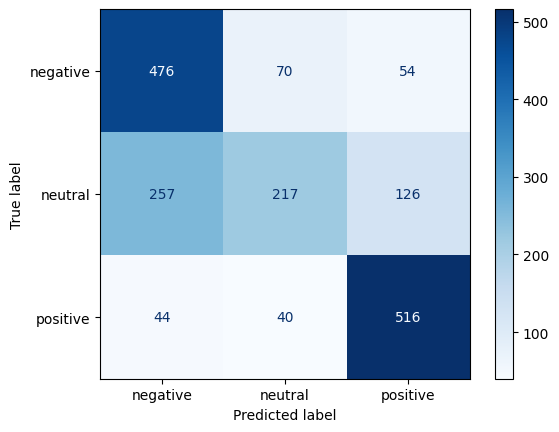

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred = trainer.predict(ds["test"])
y_pred = np.argmax(pred.predictions, axis=1)
y_true = pred.label_ids
names = ["negative", "neutral", "positive"]

print(classification_report(y_true, y_pred, target_names=names, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
df = pd.DataFrame({
    "text": ds["test"]["text"],
    "gerçek": [names[i] for i in y_true],
    "tahmin": [names[i] for i in y_pred],
})
yanlis = df[df["gerçek"] != df["tahmin"]]
print(len(yanlis), "yanlış /", len(df))
yanlis.sample(15, random_state=1)

584 yanlış / 1800


,text,gerçek,tahmin
1,ela,negative,positive
1555,"Elan yükləmək istədim , amma yüklənmədi. Bütün...",neutral,negative
1041,Eĺa,negative,positive
62,Salam sizden xaisim evelki 13 manatliq gece ta...,neutral,negative
1129,Metro paketi niyə ləvğ olundu xahiş edirəm yazın.,neutral,negative
804,Hərşey bomba kimi işləyir,positive,negative
296,Yaxşıdı amma hərdən caşdirir,neutral,positive
611,Əla çox qəşəy super,negative,positive
153,Yeni kampaniyalar gələcək və ya promokod gələc...,positive,neutral
237,Salam Birbankım açılmır səbəb nə ola bilər? Se...,neutral,negative


In [8]:
model.push_to_hub("az-sentiment-xlmr")
tok.push_to_hub("az-sentiment-xlmr")

README.md:   0%|          | 0.00/3.47k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...d7pj0lk/model.safetensors:   0%|          | 13.5kB / 1.11GB            

...

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpibswsr4c/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/twnar/az-sentiment-xlmr/commit/b1520f5b3b77a426ffa8565b7640e7649701eaf7', commit_message='Upload tokenizer', commit_description='', oid='b1520f5b3b77a426ffa8565b7640e7649701eaf7', pr_url=None, repo_url=RepoUrl('https://huggingface.co/twnar/az-sentiment-xlmr', endpoint='https://huggingface.co', repo_type='model', repo_id='twnar/az-sentiment-xlmr'), pr_revision=None, pr_num=None)

In [9]:
!pip install gradio
import gradio as gr
from transformers import pipeline

clf = pipeline("text-classification", model="twnar/az-sentiment-xlmr", top_k=None)

def predict(text):
    if not text.strip():
        return {}
    return {r["label"]: r["score"] for r in clf(text)[0]}
gr.Interface(
    fn=predict,
    inputs=gr.Textbox(label="Azərbaycanca cümlə yaz", lines=3),
    outputs=gr.Label(num_top_classes=3),
    title="Azerbaijani Sentiment Analysis",
    examples=["Bu tətbiq çox yaxşıdır!", "Proqrama girmək olmur.", "Xidmət çox pis idi."],
).launch(share=True)

config.json:   0%|          | 0.00/970 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://11df59f7bd8bf09010.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
